# 08: Success Metrics for All Models (Task 3)

Compare the logistic regression (04), gradient boosting (05), and random forest (06) models on the same held-out test set with one shared set of metrics.

**Input:** `data/processed/model_dataset_2025.csv` and `data/processed/model_dataset_2025_spec.json`, from `03_build_model_dataset.ipynb`.

**What this notebook does:**
1. Refits each model with the settings selected in its own notebook (no new tuning)
2. Checks that each refit reproduces its source notebook's test results
3. Computes probability, classification, and calibration metrics, with and without the emergency-savings (EF) questions
4. Draws calibration curves and estimates bootstrap confidence intervals
5. Explains each model with SHAP and compares which survey questions matter most
6. Saves predictions, metric tables, and SHAP importance to `outputs/task3/` for Task 4

All metrics use `weight_pop`. Models are fit with `weight_pop` rescaled to mean 1, as in the source notebooks. Classification metrics use a 0.5 threshold. The test set is not used to choose anything.

## Key results

All numbers are from the held-out 2025 test set (2,587 respondents), weighted to the U.S. adult population.

- **Gradient boosting and logistic regression perform about the same.** ROC AUC is 0.929 vs 0.925 and Brier score is 0.101 vs 0.103. The bootstrap intervals for their differences include zero, so the gap is within test-set noise.
- **Random forest is behind on every probability metric.** Its ROC AUC is 0.919 and its Brier score 0.111. It is also the least calibrated (ECE 0.049 vs 0.015 to 0.020): it overestimates risk for low-risk respondents and underestimates it for the most fragile.
- **At the 0.5 threshold, all three models flag about 77 to 78% of fragile respondents**, and about 82% of the respondents they flag are actually fragile.
- **The models do not rely only on the emergency-savings (EF) questions.** Removing all 16 lowers ROC AUC by just 0.011 to 0.013 for every model.
- **The models agree on the main drivers.** C4A, EF1, EF2, K21_d, FD3, and B2 are in every model's top 10 by SHAP importance. Gradient boosting also makes noticeable use of race and ethnicity inputs (`race_5cat` ranks 15th of 425 questions).

The bar chart in section 8 shows these comparisons, and the summary at the end puts them in plain language.

## 1. Imports and configuration

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import display
from scipy.stats import spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss,
    f1_score, log_loss, precision_score, recall_score, roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

THRESHOLD = 0.5
N_BOOTSTRAP = 500
BOOTSTRAP_SEED = 2025
SHAP_BACKGROUND_ROWS = 1000
SHAP_SEED = 2025

C:\Users\Ansa\breakthrutech\Thrivent-1A-financial-resilience-map\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load the modeling data

In [2]:
DATA_DIR = Path(".")
if not (DATA_DIR / "model_dataset_2025.csv").exists():
    DATA_DIR = Path("../data/processed")
if not (DATA_DIR / "model_dataset_2025.csv").exists():
    DATA_DIR = Path("data/processed")

data = pd.read_csv(DATA_DIR / "model_dataset_2025.csv", low_memory=False)
with open(DATA_DIR / "model_dataset_2025_spec.json", encoding="utf-8") as f:
    spec = json.load(f)

ID = spec["id"]
TARGET = spec["target"]["column"]
WEIGHT = spec["weight"]
NUMERIC = spec["features"]["numeric"]
CATEGORICAL = spec["features"]["categorical"]
ORDINAL = spec["features"]["ordinal"]
FEATURES = NUMERIC + CATEGORICAL + ORDINAL
FEATURES_NO_EF = [col for col in FEATURES if col not in spec["ef_module"]]

assert set(FEATURES + [ID, TARGET, WEIGHT, "split"]).issubset(data.columns)
assert data[ID].is_unique and set(data[TARGET].unique()) == {0, 1}
assert (data[WEIGHT] > 0).all()

train = data.loc[data["split"] == "train"].copy()
test = data.loc[data["split"] == "test"].copy()
X_train, y_train, w_train = train[FEATURES], train[TARGET], train[WEIGHT]
X_test, y_test, w_test = test[FEATURES], test[TARGET], test[WEIGHT]

TRAIN_RATE = np.average(y_train, weights=w_train)
print(f"Train: {len(train):,} rows; test: {len(test):,} rows")
print(f"Features: {len(FEATURES)} with EF; {len(FEATURES_NO_EF)} without EF")
print(f"Weighted training fragility rate: {TRAIN_RATE:.1%}")

Train: 10,347 rows; test: 2,587 rows
Features: 425 with EF; 409 without EF
Weighted training fragility rate: 36.8%


## 3. Model definitions

Preprocessing and settings are copied from each source notebook so the refits match:

| Model | Source | Selected settings |
|---|---|---|
| Logistic regression | `04_logistic_regression_baseline.ipynb` | `C=0.01` (scaled inputs) |
| Gradient boosting | `05_gradient_boosting.ipynb` | see `GB_PARAMS` |
| Random forest | `06_tree_based_model.ipynb` | `max_depth=20, min_samples_leaf=20, max_features="sqrt"`, 200 trees |

If a source notebook re-tunes and picks different settings, update them here.

In [3]:
LR_PARAMS = {"C": 0.01}
GB_PARAMS = {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 2}
RF_PARAMS = {"max_depth": 20, "min_samples_leaf": 20, "max_features": "sqrt"}


def split_types(features):
    return ([c for c in NUMERIC if c in features],
            [c for c in CATEGORICAL if c in features],
            [c for c in ORDINAL if c in features])


def linear_preprocessor(features):
    # Same as 04: scaled numeric and ordinal inputs.
    numeric, categorical, ordinal = split_types(features)
    return ColumnTransformer([
        ("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", StandardScaler()),
        ]), numeric),
        ("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
            ("one_hot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical),
        ("ordinal", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OrdinalEncoder(
                categories=[spec["features"]["ordinal_order"][c] for c in ordinal])),
            ("scale", StandardScaler()),
        ]), ordinal),
    ])


def tree_preprocessor(features):
    # Same as 05 and 06: no scaling for trees.
    numeric, categorical, ordinal = split_types(features)
    return ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median", add_indicator=True,
                                  keep_empty_features=True), numeric),
        ("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="__MISSING__")),
            ("encode", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical),
        ("ordinal", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OrdinalEncoder(
                categories=[spec["features"]["ordinal_order"][c] for c in ordinal],
                handle_unknown="use_encoded_value", unknown_value=-1)),
        ]), ordinal),
    ], sparse_threshold=1.0)


def build_model(name, features):
    if name == "Logistic regression":
        return Pipeline([("preprocess", linear_preprocessor(features)),
                         ("model", LogisticRegression(max_iter=1000, **LR_PARAMS))])
    if name == "Gradient boosting":
        return Pipeline([("preprocess", tree_preprocessor(features)),
                         ("model", GradientBoostingClassifier(
                             loss="log_loss", min_samples_leaf=20,
                             random_state=46796, **GB_PARAMS))])
    if name == "Random forest":
        return Pipeline([("preprocess", tree_preprocessor(features)),
                         ("model", RandomForestClassifier(
                             n_estimators=200, random_state=2344, n_jobs=-1,
                             **RF_PARAMS))])
    raise ValueError(name)


MODELS = ["Logistic regression", "Gradient boosting", "Random forest"]

## 4. Fit every model, with and without EF

In [4]:
fitted = {}
predictions = {}
for name in MODELS:
    for label, features in [("with EF", FEATURES), ("without EF", FEATURES_NO_EF)]:
        model = build_model(name, features)
        model.fit(X_train[features], y_train,
                  model__sample_weight=w_train / w_train.mean())
        p = model.predict_proba(X_test[features])[:, 1]
        assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
        fitted[(name, label)] = model
        predictions[(name, label)] = pd.Series(p, index=test.index)
        print(f"Fitted {name} ({label})")

Fitted Logistic regression (with EF)


Fitted Logistic regression (without EF)


Fitted Gradient boosting (with EF)


Fitted Gradient boosting (without EF)


Fitted Random forest (with EF)


Fitted Random forest (without EF)


## 5. Check the refits reproduce the source notebooks

Logistic regression is compared row by row with `logistic_test_predictions.csv`. The tree models have no saved predictions, so their ROC AUC and Brier are compared with the values printed in 05 and 06 (rounded to 3 decimals).

In [5]:
saved_lr = (pd.read_csv(DATA_DIR / "logistic_test_predictions.csv")
            .set_index(ID).loc[test[ID]])
assert np.array_equal(saved_lr["actual_fragile"].to_numpy(), y_test.to_numpy())
lr_diff = np.abs(saved_lr["predicted_probability"].to_numpy()
                 - predictions[("Logistic regression", "with EF")].to_numpy()).max()
print(f"Logistic regression: max difference from saved predictions = {lr_diff:.1e}")
assert lr_diff < 1e-6

REPORTED = {
    "Gradient boosting": {"ROC AUC": 0.929, "Brier": 0.101},
    "Random forest": {"ROC AUC": 0.919, "Brier": 0.111},
}
for name, reported in REPORTED.items():
    p = predictions[(name, "with EF")]
    actual = {
        "ROC AUC": roc_auc_score(y_test, p, sample_weight=w_test),
        "Brier": brier_score_loss(y_test, p, sample_weight=w_test),
    }
    for metric, value in reported.items():
        print(f"{name} {metric}: refit {actual[metric]:.4f}, source notebook {value:.3f}")
        assert abs(actual[metric] - value) <= 0.002, f"{name} {metric} does not match its notebook"

Logistic regression: max difference from saved predictions = 1.2e-12
Gradient boosting ROC AUC: refit 0.9288, source notebook 0.929
Gradient boosting Brier: refit 0.1007, source notebook 0.101
Random forest ROC AUC: refit 0.9188, source notebook 0.919
Random forest Brier: refit 0.1114, source notebook 0.111


## 6. Metrics

- **ROC AUC / PR AUC**: ranking quality (PR AUC focuses on the fragile class).
- **Brier score**: mean squared error of the probabilities (lower is better).
- **Brier skill score**: improvement over always predicting the training fragility rate (1 = perfect, 0 = no better).
- **Log loss**: penalizes confident wrong probabilities.
- **ECE**: weighted average gap between predicted and observed rates across 10 quantile bins.
- **Accuracy, precision, recall, F1**: at the 0.5 threshold.

In [6]:
def weighted_calibration(y_true, probabilities, weights, bins=10):
    frame = pd.DataFrame({"actual": np.asarray(y_true),
                          "predicted": np.asarray(probabilities),
                          "weight": np.asarray(weights)})
    if frame["predicted"].nunique() == 1:
        # A constant predictor (e.g. training prevalence) is one bin.
        frame["bin"] = "all"
    else:
        frame["bin"] = pd.qcut(frame["predicted"], q=bins, duplicates="drop")
    frame["weighted_actual"] = frame["actual"] * frame["weight"]
    frame["weighted_predicted"] = frame["predicted"] * frame["weight"]
    table = frame.groupby("bin", observed=True).agg(
        rows=("actual", "size"), weight=("weight", "sum"),
        weighted_actual=("weighted_actual", "sum"),
        weighted_predicted=("weighted_predicted", "sum"),
    )
    table["mean_predicted"] = table["weighted_predicted"] / table["weight"]
    table["observed_rate"] = table["weighted_actual"] / table["weight"]
    ece = np.average(abs(table["mean_predicted"] - table["observed_rate"]),
                     weights=table["weight"])
    return table[["rows", "weight", "mean_predicted", "observed_rate"]], ece


REFERENCE_BRIER = brier_score_loss(y_test, np.full(len(test), TRAIN_RATE),
                                   sample_weight=w_test)


def evaluate(y_true, probabilities, weights):
    probabilities = np.asarray(probabilities)
    predicted = probabilities >= THRESHOLD
    brier = brier_score_loss(y_true, probabilities, sample_weight=weights)
    return {
        "ROC AUC": roc_auc_score(y_true, probabilities, sample_weight=weights),
        "PR AUC": average_precision_score(y_true, probabilities, sample_weight=weights),
        "Brier": brier,
        "Brier skill": 1 - brier / REFERENCE_BRIER,
        "Log loss": log_loss(y_true, probabilities, sample_weight=weights),
        "ECE": weighted_calibration(y_true, probabilities, weights)[1],
        "Accuracy": accuracy_score(y_true, predicted, sample_weight=weights),
        "Precision": precision_score(y_true, predicted, sample_weight=weights, zero_division=0),
        "Recall": recall_score(y_true, predicted, sample_weight=weights, zero_division=0),
        "F1": f1_score(y_true, predicted, sample_weight=weights, zero_division=0),
    }


rows = [{"model": "Training prevalence", "features": "none",
         **evaluate(y_test, np.full(len(test), TRAIN_RATE), w_test)}]
for (name, label), p in predictions.items():
    rows.append({"model": name, "features": label, **evaluate(y_test, p, w_test)})
metrics = pd.DataFrame(rows)

pd.set_option("display.width", 200)
display(metrics.set_index(["features", "model"]).sort_index().round(3))

ROC AUC  PR AUC  Brier  Brier skill  Log loss    ECE  Accuracy  Precision  Recall     F1
features   model                                                                                                        
none       Training prevalence    0.500   0.370  0.233        0.000     0.659  0.002     0.630      0.000   0.000  0.000
with EF    Gradient boosting      0.929   0.881  0.101        0.568     0.329  0.020     0.858      0.825   0.782  0.803
           Logistic regression    0.925   0.875  0.103        0.560     0.335  0.015     0.856      0.821   0.780  0.800
           Random forest          0.919   0.869  0.111        0.522     0.360  0.049     0.851      0.819   0.767  0.792
without EF Gradient boosting      0.916   0.856  0.111        0.524     0.357  0.016     0.846      0.809   0.765  0.787
           Logistic regression    0.914   0.855  0.112        0.519     0.359  0.016     0.845      0.805   0.768  0.786
           Random forest          0.907   0.848  0.122        0.477     0.389  0.057     0.830      0.793   0.734  0.762

**How much do the EF questions add?** Change in each metric when the 16 EF questions are removed (without EF minus with EF).

In [7]:
indexed = metrics.set_index(["model", "features"])
ef_drop = (indexed.xs("without EF", level="features")
           - indexed.xs("with EF", level="features"))
display(ef_drop[["ROC AUC", "PR AUC", "Brier", "Log loss", "ECE", "Recall"]].round(3))

,ROC AUC,PR AUC,Brier,Log loss,ECE,Recall
model,,,,,,
Logistic regression,-0.011,-0.020,0.01,0.024,0.001,-0.011
Gradient boosting,-0.013,-0.025,0.01,0.028,-0.004,-0.016
Random forest,-0.012,-0.021,0.01,0.029,0.008,-0.033


## 7. Calibration curves

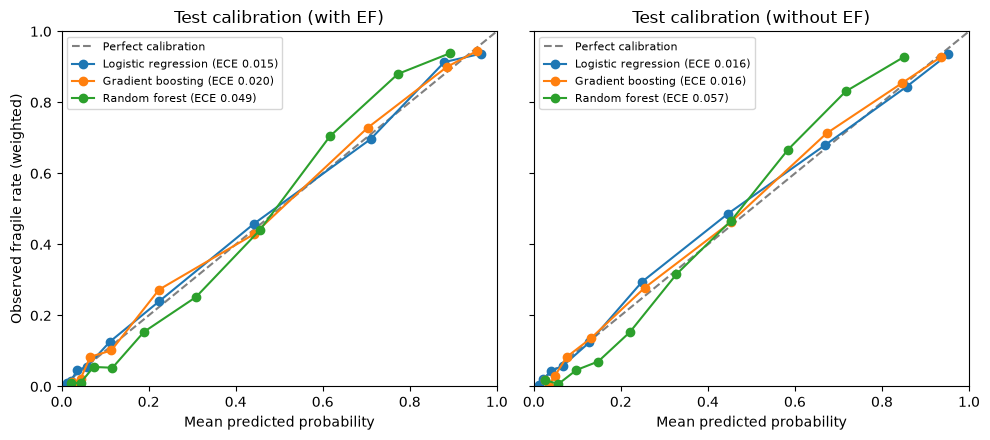

In [8]:
calibration_rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, label in zip(axes, ["with EF", "without EF"]):
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
    for name in MODELS:
        table, ece = weighted_calibration(y_test, predictions[(name, label)], w_test)
        ax.plot(table["mean_predicted"], table["observed_rate"], "o-",
                label=f"{name} (ECE {ece:.3f})")
        calibration_rows.append(table.reset_index().assign(model=name, features=label))
    ax.set(xlabel="Mean predicted probability", title=f"Test calibration ({label})",
           xlim=(0, 1), ylim=(0, 1))
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("Observed fragile rate (weighted)")
fig.tight_layout()
plt.show()

calibration_bins = pd.concat(calibration_rows, ignore_index=True)
calibration_bins["bin"] = calibration_bins["bin"].astype(str)

## 8. Bootstrap confidence intervals

Resample test respondents with replacement (predictions stay fixed) to see whether the differences between models are larger than test-set noise. Intervals are 2.5th to 97.5th percentiles. The paired differences use the same resample for both models.

In [9]:
rng = np.random.default_rng(BOOTSTRAP_SEED)
y_arr, w_arr = y_test.to_numpy(), w_test.to_numpy()
p_arr = {name: predictions[(name, "with EF")].to_numpy() for name in MODELS}
BOOT_METRICS = {
    "ROC AUC": lambda y, p, w: roc_auc_score(y, p, sample_weight=w),
    "Brier": lambda y, p, w: brier_score_loss(y, p, sample_weight=w),
    "ECE": lambda y, p, w: weighted_calibration(y, p, w)[1],
}

draws = []
for b in range(N_BOOTSTRAP):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    for name in MODELS:
        for metric, fn in BOOT_METRICS.items():
            draws.append({"draw": b, "model": name, "metric": metric,
                          "value": fn(y_arr[idx], p_arr[name][idx], w_arr[idx])})
draws = pd.DataFrame(draws)

intervals = (draws.groupby(["metric", "model"])["value"]
             .quantile([0.025, 0.975]).unstack()
             .rename(columns={0.025: "lower", 0.975: "upper"}))
point = metrics[metrics["features"] == "with EF"].set_index("model")
intervals["estimate"] = [point.loc[m, metric] for metric, m in intervals.index]
display(intervals[["estimate", "lower", "upper"]].round(3))

wide = draws.pivot_table(index=["draw", "metric"], columns="model", values="value")
pairs = [("Gradient boosting", "Logistic regression"),
         ("Gradient boosting", "Random forest"),
         ("Logistic regression", "Random forest")]
paired = []
for a, b in pairs:
    for metric in BOOT_METRICS:
        diff = (wide[a] - wide[b]).xs(metric, level="metric")
        paired.append({"comparison": f"{a} - {b}", "metric": metric,
                       "lower": diff.quantile(0.025), "upper": diff.quantile(0.975),
                       "share of draws > 0": (diff > 0).mean()})
paired = pd.DataFrame(paired)
display(paired.set_index(["metric", "comparison"]).round(3))

estimate  lower  upper
metric  model                                      
Brier   Gradient boosting       0.101  0.092  0.108
        Logistic regression     0.103  0.094  0.111
        Random forest           0.111  0.104  0.118
ECE     Gradient boosting       0.020  0.014  0.034
        Logistic regression     0.015  0.013  0.033
        Random forest           0.049  0.039  0.063
ROC AUC Gradient boosting       0.929  0.919  0.939
        Logistic regression     0.925  0.914  0.937
        Random forest           0.919  0.907  0.931

,,lower,upper,share of draws > 0
metric,comparison,,,
ROC AUC,Gradient boosting - Logistic regression,-0.000,0.007,0.970
Brier,Gradient boosting - Logistic regression,-0.005,0.001,0.116
ECE,Gradient boosting - Logistic regression,-0.011,0.013,0.616
ROC AUC,Gradient boosting - Random forest,0.006,0.014,1.000
Brier,Gradient boosting - Random forest,-0.014,-0.008,0.000
ECE,Gradient boosting - Random forest,-0.043,-0.012,0.000
ROC AUC,Logistic regression - Random forest,0.002,0.011,0.998
Brier,Logistic regression - Random forest,-0.013,-0.005,0.000
ECE,Logistic regression - Random forest,-0.043,-0.012,0.000


**Model comparison at a glance.** Bars are test-set estimates and the black lines are each model's own bootstrap 95% interval. Higher is better for ROC AUC; lower is better for Brier and ECE. The ROC AUC axis starts at 0.88 so the differences are visible. Because all models are scored on the same respondents, the paired differences in the table above are the better test: random forest is reliably worse than both other models even where its interval overlaps theirs, while gradient boosting and logistic regression are within noise of each other.

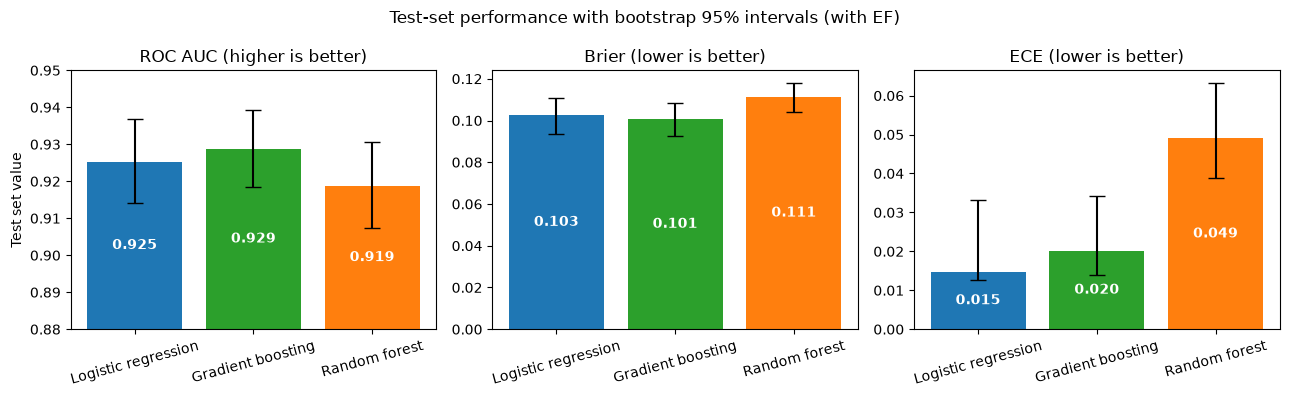

In [10]:
COLORS = {"Logistic regression": "tab:blue", "Gradient boosting": "tab:green",
          "Random forest": "tab:orange"}
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, metric in zip(axes, ["ROC AUC", "Brier", "ECE"]):
    rows = intervals.loc[metric].loc[MODELS]
    errors = [rows["estimate"] - rows["lower"], rows["upper"] - rows["estimate"]]
    bars = ax.bar(MODELS, rows["estimate"], yerr=errors, capsize=6,
                  color=[COLORS[m] for m in MODELS])
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in rows["estimate"]],
                 label_type="center", color="white", fontweight="bold")
    better = "higher is better" if metric == "ROC AUC" else "lower is better"
    ax.set_title(f"{metric} ({better})")
    ax.tick_params(axis="x", labelrotation=15)
    if metric == "ROC AUC":
        ax.set_ylim(0.88, 0.95)
axes[0].set_ylabel("Test set value")
fig.suptitle("Test-set performance with bootstrap 95% intervals (with EF)")
fig.tight_layout()
plt.show()

## 9. SHAP explanations

SHAP splits each test respondent's prediction into a contribution from each input. One-hot columns are summed back to their survey question, so each question gets one value per respondent. A question's importance is its survey-weighted mean |SHAP| over the test set.

- **Gradient boosting / random forest:** `TreeExplainer` (exact for trees).
- **Logistic regression:** `LinearExplainer` with a background of 1,000 training rows.
- Gradient boosting and logistic regression are explained in log-odds and random forest in probability (each explainer's native output), so models are compared by **rank and share of total importance**, not raw values.
- SHAP describes how each model uses the inputs. It does not show that a question causes financial fragility.

The additivity check confirms that, for every respondent, the base value plus the SHAP values reproduces the model's own output.

In [11]:
def question_names(preprocessor):
    # Map each encoded column back to the survey question it came from.
    names = []
    for kind, transformer, columns in preprocessor.transformers_:
        if kind == "categorical":
            encoder = transformer[-1]
            for col, levels in zip(columns, encoder.categories_):
                names += [col] * len(levels)
        else:
            for name in transformer.get_feature_names_out(columns):
                names.append(name.removeprefix("missingindicator_"))
    return np.array(names)


def dense(matrix):
    return matrix.toarray() if hasattr(matrix, "toarray") else np.asarray(matrix)


background_index = (train.sample(SHAP_BACKGROUND_ROWS, random_state=SHAP_SEED).index)
shap_by_question = {}
for name in MODELS:
    pipeline = fitted[(name, "with EF")]
    prep, model = pipeline.named_steps["preprocess"], pipeline.named_steps["model"]
    X_encoded = dense(prep.transform(X_test))
    questions = question_names(prep)
    assert len(questions) == X_encoded.shape[1]

    if name == "Logistic regression":
        background = dense(prep.transform(X_train.loc[background_index]))
        explainer = shap.LinearExplainer(model, shap.maskers.Independent(background, max_samples=SHAP_BACKGROUND_ROWS))
        values = explainer.shap_values(X_encoded)
        base = explainer.expected_value
        model_output = model.decision_function(X_encoded)
    else:
        explainer = shap.TreeExplainer(model)
        values = explainer.shap_values(X_encoded)
        base = explainer.expected_value
        if name == "Random forest":
            # Explain the probability of the fragile class.
            values = values[:, :, 1] if np.ndim(values) == 3 else values[1]
            base = np.ravel(base)[1]
            model_output = model.predict_proba(X_encoded)[:, 1]
        else:
            model_output = model.decision_function(X_encoded)
    base = float(np.ravel(base)[0])

    gap = np.abs(base + values.sum(axis=1) - model_output).max()
    print(f"{name}: max additivity gap = {gap:.1e}")
    assert gap < 1e-4

    shap_by_question[name] = (pd.DataFrame(values, index=test.index)
                              .T.groupby(questions).sum().T)

Logistic regression: max additivity gap = 2.2e-15


Gradient boosting: max additivity gap = 4.9e-15


Random forest: max additivity gap = 1.7e-15


In [12]:
importance_rows = []
for name, frame in shap_by_question.items():
    mean_abs = frame.abs().mul(w_test, axis=0).sum() / w_test.sum()
    importance_rows.append(pd.DataFrame({
        "model": name,
        "question": mean_abs.index,
        "mean_abs_shap": mean_abs.to_numpy(),
        "share": (mean_abs / mean_abs.sum()).to_numpy(),
        "in_ef_module": mean_abs.index.isin(spec["ef_module"]),
    }))
shap_importance = pd.concat(importance_rows, ignore_index=True)
shap_importance["rank"] = (shap_importance.groupby("model")["mean_abs_shap"]
                           .rank(ascending=False, method="first").astype(int))
shap_importance = shap_importance.sort_values(["model", "rank"]).reset_index(drop=True)

top = (shap_importance[shap_importance["rank"] <= 15]
       .pivot(index="rank", columns="model", values="question"))
print("Top 15 questions by weighted mean |SHAP|")
display(top[MODELS])

ef_share = shap_importance.groupby("model").apply(
    lambda g: g.loc[g["in_ef_module"], "share"].sum(), include_groups=False)
print("Share of total importance from the 16 EF questions:")
display(ef_share.rename("EF share").to_frame().round(3))

Top 15 questions by weighted mean |SHAP|


model,Logistic regression,Gradient boosting,Random forest
rank,,,
1,C4A,C4A,EF1
2,EF1,EF2,EF2
3,EF2,EF1,atleast_okay
4,B1_a,EF7,K21_d
5,K21_d,EF7A,C4A
6,FD3,FD3,B2
7,EF7,A6,EF8_j
8,I20,B2,EF8_e
9,EF7A,K21_d,A6


Share of total importance from the 16 EF questions:


,EF share
model,
Gradient boosting,0.356
Logistic regression,0.136
Random forest,0.342


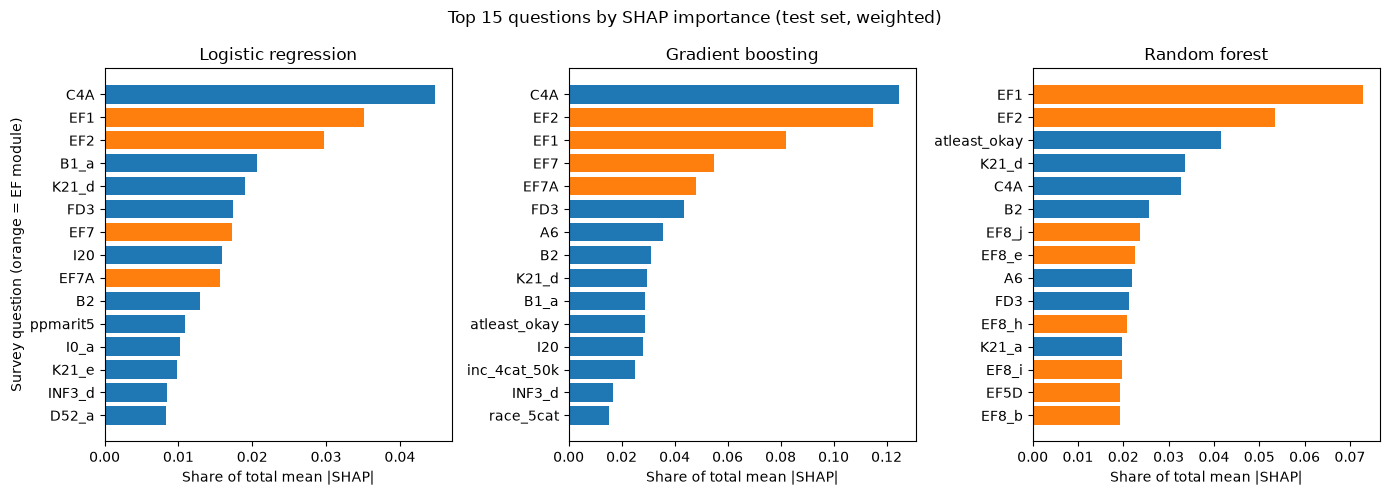

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, name in zip(axes, MODELS):
    rows = shap_importance[(shap_importance["model"] == name)
                           & (shap_importance["rank"] <= 15)].iloc[::-1]
    colors = ["tab:orange" if ef else "tab:blue" for ef in rows["in_ef_module"]]
    ax.barh(rows["question"], rows["share"], color=colors)
    ax.set(title=name, xlabel="Share of total mean |SHAP|")
axes[0].set_ylabel("Survey question (orange = EF module)")
fig.suptitle("Top 15 questions by SHAP importance (test set, weighted)")
fig.tight_layout()
plt.show()

**Do the models agree?** Spearman rank correlation of question importance between each pair of models, over all questions and over the union of each pair's top 20. Overlap counts how many top-20 questions the two models share.

In [14]:
ranks = shap_importance.pivot(index="question", columns="model", values="mean_abs_shap")
agreement = []
for a, b in [("Gradient boosting", "Logistic regression"),
             ("Gradient boosting", "Random forest"),
             ("Logistic regression", "Random forest")]:
    top_a = set(ranks[a].nlargest(20).index)
    top_b = set(ranks[b].nlargest(20).index)
    union = sorted(top_a | top_b)
    agreement.append({
        "comparison": f"{a} vs {b}",
        "Spearman (all questions)": spearmanr(ranks[a], ranks[b]).statistic,
        "Spearman (top-20 union)": spearmanr(ranks.loc[union, a], ranks.loc[union, b]).statistic,
        "top-20 overlap": len(top_a & top_b),
    })
display(pd.DataFrame(agreement).set_index("comparison").round(3))

,Spearman (all questions),Spearman (top-20 union),top-20 overlap
comparison,,,
Gradient boosting vs Logistic regression,0.489,0.474,12
Gradient boosting vs Random forest,0.542,0.211,11
Logistic regression vs Random forest,0.661,-0.016,7


**Logistic-regression coefficients vs SHAP.** A question's coefficient importance is its largest |coefficient| across its encoded columns. Both rankings come from the same model, so differences come from how SHAP weights each coefficient by how much respondents actually vary on that input: a large coefficient on a rare answer contributes little SHAP on average.

In [15]:
lr_pipeline = fitted[("Logistic regression", "with EF")]
lr_questions = question_names(lr_pipeline.named_steps["preprocess"])
coefficients = pd.Series(lr_pipeline.named_steps["model"].coef_[0])
coef_importance = coefficients.abs().groupby(lr_questions).max()

lr_shap = ranks["Logistic regression"]
comparison = pd.DataFrame({
    "max |coefficient|": coef_importance,
    "coefficient rank": coef_importance.rank(ascending=False, method="first").astype(int),
    "SHAP rank": lr_shap.rank(ascending=False, method="first").astype(int),
})
rho = spearmanr(comparison["max |coefficient|"], lr_shap.loc[comparison.index]).statistic
print(f"Spearman correlation, coefficient vs SHAP importance: {rho:.3f}")
display(comparison.sort_values("coefficient rank").head(15).round(3))

Spearman correlation, coefficient vs SHAP importance: 0.761


,max |coefficient|,coefficient rank,SHAP rank
C4A,0.554,1,1
EF7A,0.445,2,9
EF7,0.425,3,7
EF2,0.325,4,3
B1_a,0.298,5,4
EF1,0.287,6,2
FD3,0.218,7,6
I20,0.170,8,8
ppcm0160,0.169,9,73
K21_d,0.162,10,5


## 10. Save outputs for Task 4

In [16]:
OUT = Path("../outputs/task3") if Path("../data/processed").exists() else Path("outputs/task3")
OUT.mkdir(parents=True, exist_ok=True)

slug = {"Logistic regression": "lr", "Gradient boosting": "gb", "Random forest": "rf"}
saved = test[[ID, TARGET, WEIGHT]].rename(columns={TARGET: "actual_fragile"})
for (name, label), p in predictions.items():
    suffix = "" if label == "with EF" else "_no_ef"
    saved[f"p_{slug[name]}{suffix}"] = p
saved.to_csv(OUT / "test_predictions.csv", index=False)
metrics.to_csv(OUT / "metrics.csv", index=False)
calibration_bins.to_csv(OUT / "calibration_bins.csv", index=False)
intervals.reset_index().to_csv(OUT / "bootstrap_intervals.csv", index=False)
paired.to_csv(OUT / "bootstrap_paired_differences.csv", index=False)
shap_importance.to_csv(OUT / "shap_importance.csv", index=False)
print("Saved to", OUT.resolve())
for path in sorted(OUT.glob("*.csv")):
    print(" ", path.name)

Saved to C:\Users\Ansa\breakthrutech\Thrivent-1A-financial-resilience-map\outputs\task3
  bootstrap_intervals.csv
  bootstrap_paired_differences.csv
  calibration_bins.csv
  metrics.csv
  shap_importance.csv
  test_predictions.csv


## Summary

We compared three models that estimate whether a U.S. adult could not cover a $400 emergency expense with cash or its equivalent. All three were tested on the same held-out respondents and scored with population weights. Gradient boosting and logistic regression perform equally well. Both rank fragile respondents above non-fragile ones about 93% of the time (ROC AUC), and their predicted probabilities closely match observed rates. Their small differences are within what we would expect from test-set noise. Random forest is consistently, if modestly, worse and is the least well calibrated. Every model flags roughly four in five fragile respondents at a 0.5 threshold and keeps most of its accuracy when the emergency-savings questions are removed. SHAP shows that the models agree on a common set of driving questions, and that logistic regression's coefficients and SHAP values largely tell the same story. These results describe associations in the survey, not causes. They are meant to support human judgement, not to score individuals. Choosing the final model, and deciding how to handle protected attributes such as race and ethnicity among the inputs, are left for Task 4.